# 3. Decision Tree Regression & Random Forest Regression

## Lý thuyết & Nguyên lý

### 3.1. Decision Tree Regression (Thuật toán CART)

Decision Tree Regression chia không gian đặc trưng thành các **vùng hình chữ nhật** bằng các **vách ngăn vuông góc** với trục tọa độ. Trong mỗi vùng, mô hình dự đoán bằng **giá trị trung bình** của các điểm dữ liệu thuộc vùng đó.

Cách chọn điểm chia tốt nhất (*Recursive Binary Splitting*): tìm biến $X_j$ và ngưỡng $s$ để tối thiểu hóa tổng bình phương sai số (MSE) của hai nhánh con:

$$\min_{j,\,s}\left[\min_{c_1}\sum_{x_i \in R_1(j,s)}(y_i - c_1)^2 \;+\; \min_{c_2}\sum_{x_i \in R_2(j,s)}(y_i - c_2)^2\right]$$

trong đó $R_1(j,s)=\{X \mid X_j < s\}$, $R_2(j,s)=\{X \mid X_j \ge s\}$, và $c_1, c_2$ chính là **trung bình** của $y$ trong vùng tương ứng (nên phương sai trong mỗi vùng được tối thiểu hóa).

Quá trình chia lặp lại đệ quy cho đến khi thỏa một **điều kiện dừng**: `max_depth`, `min_samples_split`, `min_samples_leaf`, hoặc MSE xuống dưới ngưỡng cho phép.

- **Đặc điểm:** dự đoán có dạng **bước thang** (step function), đứt đoạn tại các ngưỡng chia.
- **Không yêu cầu chuẩn hóa** dữ liệu vì điểm chia chỉ dựa trên thứ tự giá trị.
- **Dễ overfitting** nếu cây trồng sâu — cây nhớ cả nhiễu (noise) trong dữ liệu huấn luyện.

### 3.2. Random Forest Regression (Bagging + Chọn đặc trưng ngẫu nhiên)

Random Forest thuộc nhóm **Bagging** (Bootstrap Aggregating). Huấn luyện song song $B$ cây quyết định độc lập, mỗi cây trên:

1. Một **bản bootstrap** (rút mẫu có hoàn lại) của dữ liệu huấn luyện.
2. Một **tập con ngẫu nhiên** khoảng $\sqrt{p}$ đặc trưng (regression thường dùng khoảng $p/3$) tại mỗi lần chọn điểm chia.

Dự đoán cuối cùng là **trung bình** các dự đoán của từng cây:

$$\hat{y}_{\text{RF}}(x) = \frac{1}{B}\sum_{b=1}^{B} T_b(x)$$

Nếu $B$ cây độc lập, phương sai của trung bình giảm theo hệ số $1/B$. Trong thực tế các cây vẫn **tương quan** với nhau (vì cùng dữ liệu), nên hiệu ứng giảm phương sai bị hạn chế — đó chính là lý do phải **randomize tập đặc trưng** ở bước chọn điểm chia: nó làm giảm độ tương quan giữa các cây và giúp phương sai giảm mạnh hơn.

Một chỉ số đánh giá nội bộ tiện lợi: **OOB (Out-Of-Bag)** — mỗi cây bootstrap bỏ lại khoảng 36.8% mẫu không được rút tới; dùng chính những mẫu OOB này để kiểm định cây, thu được ước lượng lỗi **không cần tách tập validation riêng**.


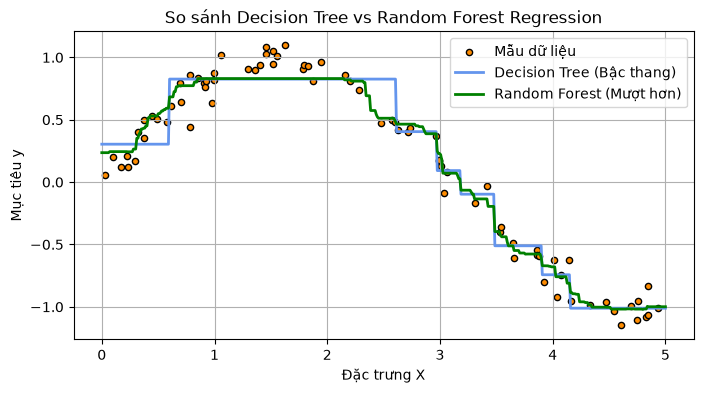

In [1]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor

# 1. Tạo dữ liệu giả lập: quan hệ phi tuyến (hàm sin) + nhiễu Gauss
np.random.seed(42)
X = np.sort(5 * np.random.rand(80, 1), axis=0)
y = np.sin(X).ravel() + np.random.normal(0, 0.1, X.shape[0])

# 2. Huấn luyện Decision Tree (độ sâu 3) và Random Forest (50 cây)
tree = DecisionTreeRegressor(max_depth=3, random_state=42).fit(X, y)
forest = RandomForestRegressor(n_estimators=50, max_depth=3, random_state=42).fit(X, y)

# 3. Dữ liệu test mịn để vẽ đường dự đoán
X_test = np.linspace(0, 5, 500)[:, np.newaxis]

plt.figure(figsize=(8, 4))
plt.scatter(X, y, s=20, edgecolor='black', c='darkorange', label='Mẫu dữ liệu')
plt.plot(
    X_test,
    tree.predict(X_test),
    color='cornflowerblue',
    label='Decision Tree (Bậc thang)',
    linewidth=2,
)
plt.plot(
    X_test,
    forest.predict(X_test),
    color='green',
    label='Random Forest (Mượt hơn)',
    linewidth=2,
)
plt.title('So sánh Decision Tree vs Random Forest Regression')
plt.xlabel('Đặc trưng X')
plt.ylabel('Mục tiêu y')
plt.legend()
plt.grid(True)
plt.show()


## Ý nghĩa của biểu đồ

- Đường **xanh dương** (Decision Tree): các dự đoán nằm ngang rồi nhảy vọt — đó là các **ngưỡng chia** của cây; độ sâu 3 chỉ tạo tối đa 4 vùng, nên đường dự đoán còn rất thô.
- Đường **xanh lá** (Random Forest): trung bình 50 cây, mỗi cây chia dữ liệu theo bootstrap + đặc trưng ngẫu nhiên riêng → các bậc thang "trộn" vào nhau và tạo thành đường cong **mượt hơn, bám sát hàm sin** hơn.

---

## Tổng quan mô hình

### Ưu điểm

- **Không giả định quan hệ tuyến tính:** bắt được cả quan hệ phi tuyến, tương tác giữa các đặc trưng một cách tự động.
- **Dễ diễn giải:** có thể in cây ra dạng đồ thị hoặc truy vết từng dự đoán theo quy tắc `if-then`.
- **Không cần chuẩn hóa/scaling:** điểm chia dựa trên thứ tự giá trị, không dựa trên khoảng cách.
- **Random Forest rất mạnh làm mô hình mặc định:** hiệu năng cao trên nhiều loại dữ liệu bảng (tabular), ít tốn công tinh chỉnh.
- **Đo lường được mức độ quan trọng của đặc trưng** (`feature_importances_`).

### Nhược điểm

- **Cây đơn phương sai cao (overfitting):** độ sâu lớn sẽ khớp cả nhiễu; ngoài miền dữ liệu huấn luyện, dự đoán bậc thang kém ổn định.
- **Hồi quy bậc thang:** không extrapolate được — với $x$ ngoài vùng huấn luyện, giá trị dự đoán vẫn bằng trung bình của vùng rìa.
- **Random Forest tốn tài nguyên:** huấn luyện và suy luận chậm hơn cây đơn, mô hình "đen box" hơn.
- **Mất cân bằng dữ liệu:** điểm ngoại lai (outliers) ảnh hưởng mạnh tới trung bình của từng vùng.

### Siêu tham số quan trọng

| Tham số | Vai trò | Gợi ý |
| :--- | :--- | :--- |
| `max_depth` | Giới hạn chiều sâu cây, chống overfitting | Cây đơn: 3–10; RF: để `None` và kiểm soát qua leaf |
| `min_samples_split` | Số mẫu tối thiểu để tiếp tục chia một nút | Tăng lên khi dữ liệu nhỏ để tránh chia quá chi tiết |
| `min_samples_leaf` | Số mẫu tối thiểu trong mỗi lá | 1–5; tăng lên giúp ranh giới mượt hơn |
| `max_features` | Số đặc trưng xét tại mỗi điểm chia | Regression mặc định `1.0` (RF: dùng `0.3`–`0.5`) |
| `n_estimators` | Số cây trong rừng | RF: 100–500; thêm cây luôn giảm phương sai, không gây overfitting |

### Các trường hợp sử dụng thực tế

| Lĩnh vực | Ứng dụng cụ thể | Đặc trưng đầu vào ($X$) | Mục tiêu ($y$) |
| :--- | :--- | :--- | :--- |
| **Tài chính** | Ước lượng rủi ro tín dụng | Thu nhập, lịch sử trả nợ, số khoản vay | Điểm rủi ro / số tiền mất mát |
| **Bất động sản** | Định giá nhà theo quy tắc | Diện tích, tuổi nhà, số tầng, khoảng cách trung tâm | Giá bán dự kiến |
| **Năng lượng** | Dự báo sản lượng điện gió | Tốc độ gió, hướng gió, nhiệt độ, độ cao | Công suất phát (MW) |
| **Y tế** | Ước tính chiều cao/tuổi xương | Chiều cao, cân nặng, chỉ số sinh trắc | Tuổi xương / chỉ số lâm sàng |
| **Sản xuất** | Dự đoán thời gian hỏng thiết bị | Giờ hoạt động, số chu kỳ bảo dưỡng, rung động | Số giờ còn lại (RUL) |

### Mẹo thực hành

- Luôn so sánh với **Random Forest** thay vì chỉ một cây — cây đơn hầu như luôn có phương sai cao hơn.
- Dùng `oob_score=True` để có ngay một ước lượng lỗi validation nội bộ không cần tách dữ liệu.
- Nếu cần mô hình giải thích được nhưng vẫn mạnh, hãy thử `max_depth` nhỏ cho Random Forest hoặc dùng độ sâu cây quyết định làm baseline.


Decision Tree (depth=1) - Test MSE : 0.1111
Decision Tree (depth=20) - Train MSE: 0.0000
Decision Tree (depth=20) - Test MSE : 0.0710
Random Forest (300 trees) - Test MSE: 0.0539
Random Forest - OOB R2             : 0.8925


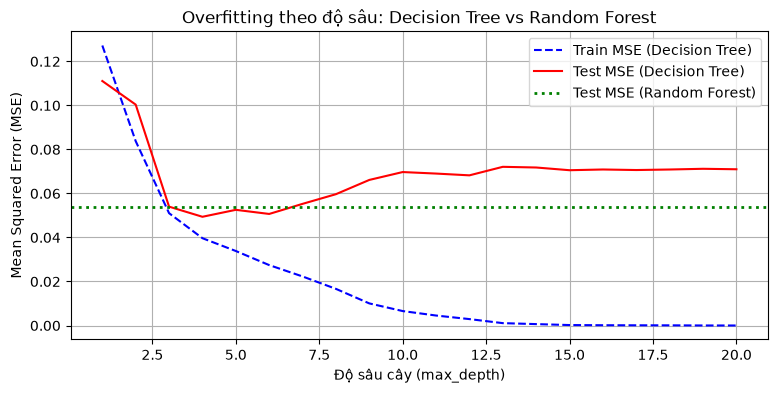

In [2]:
import matplotlib.pyplot as plt
import numpy as np
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeRegressor

# 1. Dữ liệu lớn hơn để thấy rõ hiện tượng overfitting theo độ sâu
np.random.seed(42)
X = np.sort(6 * np.random.rand(400, 1), axis=0)
y = np.sin(X).ravel() + np.random.normal(0, 0.2, X.shape[0])
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# 2. Đo MSE trên train/test theo độ sâu của cây đơn
depths = range(1, 21)
train_mse, test_mse = [], []
for d in depths:
    tree = DecisionTreeRegressor(max_depth=d, random_state=42).fit(X_train, y_train)
    train_mse.append(mean_squared_error(y_train, tree.predict(X_train)))
    test_mse.append(mean_squared_error(y_test, tree.predict(X_test)))

# 3. Random Forest 300 cây + đánh giá nội bộ OOB (Out-Of-Bag)
rf = RandomForestRegressor(n_estimators=300, random_state=42, oob_score=True).fit(X_train, y_train)
rf_test_mse = mean_squared_error(y_test, rf.predict(X_test))

print(f"Decision Tree (depth=1) - Test MSE : {test_mse[0]:.4f}")
print(f"Decision Tree (depth=20) - Train MSE: {train_mse[-1]:.4f}")
print(f"Decision Tree (depth=20) - Test MSE : {test_mse[-1]:.4f}")
print(f"Random Forest (300 trees) - Test MSE: {rf_test_mse:.4f}")
print(f"Random Forest - OOB R2             : {rf.oob_score_:.4f}")

plt.figure(figsize=(9, 4))
plt.plot(list(depths), train_mse, 'b--', label='Train MSE (Decision Tree)')
plt.plot(list(depths), test_mse, 'r-', label='Test MSE (Decision Tree)')
plt.axhline(rf_test_mse, color='green', linestyle=':', linewidth=2,
            label='Test MSE (Random Forest)')
plt.xlabel('Độ sâu cây (max_depth)')
plt.ylabel('Mean Squared Error (MSE)')
plt.title('Overfitting theo độ sâu: Decision Tree vs Random Forest')
plt.legend()
plt.grid(True)
plt.show()


## Giải thích biểu đồ trên

- **Đường xanh (Train MSE):** giảm liên tục về 0 khi cây sâu dần — cây đủ sâu thì mỗi lá gần như chứa 1 mẫu, nên khớp hoàn toàn dữ liệu huấn luyện.
- **Đường đỏ (Test MSE):** giảm nhanh ở đầu (độ sâu 1→5), chạm đáy rồi **tăng trở lại** khi cây quá sâu — dấu hiệu kinh điển của **overfitting** (variance cao).
- **Đường xanh lá ngang (Random Forest):** phương sai test gần như không phụ thuộc độ sâu vì đã được kiểm soát bằng trung bình 300 cây + bootstrap; chứng tỏ Bagging "sửa" đúng điểm yếu của cây đơn.
